# RiskQL — Risk Indicator Analysis

This notebook connects to the RiskQL PostgreSQL database, runs analytical SQL,
and visualises the operational-risk and supporting indicators.

> **Data disclaimer.** All data is **synthetic and fictitious**, produced by
> `src/generate_data.py` (seeded). It does not represent any real person,
> account, transaction, or institution. Patterns shown here are analytical
> **indicators** for learning purposes — they do not prove fraud or financial
> crime.

**Prerequisites**
1. Schema + reference data loaded: `psql "$DATABASE_URL" -f sql/run_schema.sql`
2. Data generated & loaded: `python src/generate_data.py` then
   `psql "$DATABASE_URL" -f sql/load_data.sql`
3. A `.env` file (copy from `.env.example`) with `DATABASE_URL` set.


In [1]:
import os, sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Make the local src/ package importable regardless of the working directory.
SRC = os.path.abspath(os.path.join(os.getcwd(), "..", "src"))
if SRC not in sys.path:
    sys.path.insert(0, SRC)
from db import get_engine  # reads DATABASE_URL from the environment / .env

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

engine = get_engine()

# Save charts here so the README and report can embed them.
FIG_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "reports", "figures"))
os.makedirs(FIG_DIR, exist_ok=True)

def q(sql: str) -> pd.DataFrame:
    """Run SQL and return a DataFrame."""
    return pd.read_sql(sql, engine)

def savefig(name: str):
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=110, bbox_inches="tight")

print("Connected. Row counts:")
print(q("""
    SELECT 'transactions' AS t, count(*) AS n FROM transactions
    UNION ALL SELECT 'accounts', count(*) FROM accounts
    UNION ALL SELECT 'customers', count(*) FROM customers
    UNION ALL SELECT 'login_events', count(*) FROM login_events
    ORDER BY 1
""").to_string(index=False))


Connected. Row counts:
           t     n
    accounts  3130
   customers  2000
login_events 15000
transactions 40000


## 1. Transaction volume and failure rate by channel

*Business question: which channels carry the most activity, and which fail
most often?* (Operational risk — the project's primary focus.)

,channel_name,total_txns,failed,failure_rate_pct
0,MOBILE_APP,15928,1185,7.44
1,INTERNET_BANKING,8050,878,10.91
2,POS,5255,623,11.86
3,ATM,4751,425,8.95
4,BRANCH,3957,143,3.61
5,PHONE_BANKING,2059,132,6.41


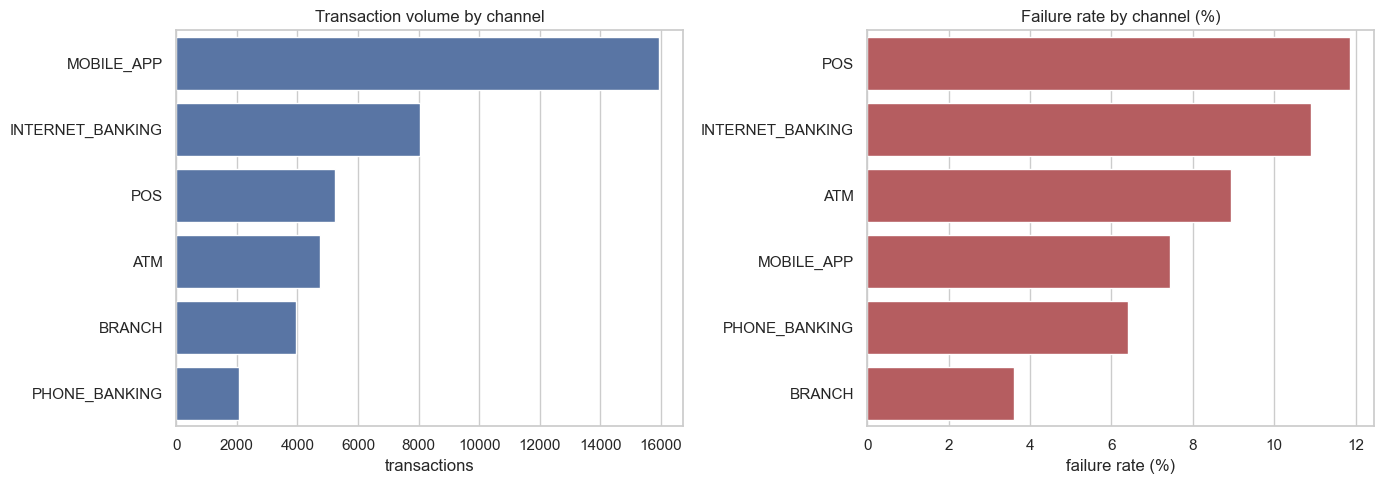

In [2]:
ch = q("""
    SELECT c.channel_name,
           count(*) AS total_txns,
           count(*) FILTER (WHERE t.status='FAILED') AS failed,
           ROUND(100.0*count(*) FILTER (WHERE t.status='FAILED')/count(*),2) AS failure_rate_pct
    FROM transactions t JOIN channels c ON c.channel_id=t.channel_id
    GROUP BY c.channel_name ORDER BY total_txns DESC
""")
display(ch)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=ch, x="total_txns", y="channel_name", color="#4C72B0", ax=ax[0])
ax[0].set_title("Transaction volume by channel"); ax[0].set_xlabel("transactions"); ax[0].set_ylabel("")
ch_s = ch.sort_values("failure_rate_pct", ascending=False)
sns.barplot(data=ch_s, x="failure_rate_pct", y="channel_name", color="#C44E52", ax=ax[1])
ax[1].set_title("Failure rate by channel (%)"); ax[1].set_xlabel("failure rate (%)"); ax[1].set_ylabel("")
savefig("01_channel_volume_failure.png"); plt.show()


## 2. Failure rate by transaction type

*Business question: do some transaction types fail more than others?*

,type_name,total_txns,failure_rate_pct
0,INTERNATIONAL_REMITTANCE,4057,13.31
1,BILL_PAYMENT,6157,9.34
2,CARD_PAYMENT,5891,8.42
3,WITHDRAWAL,6029,8.39
4,DEPOSIT,5959,7.40
5,TRANSFER,11907,6.95


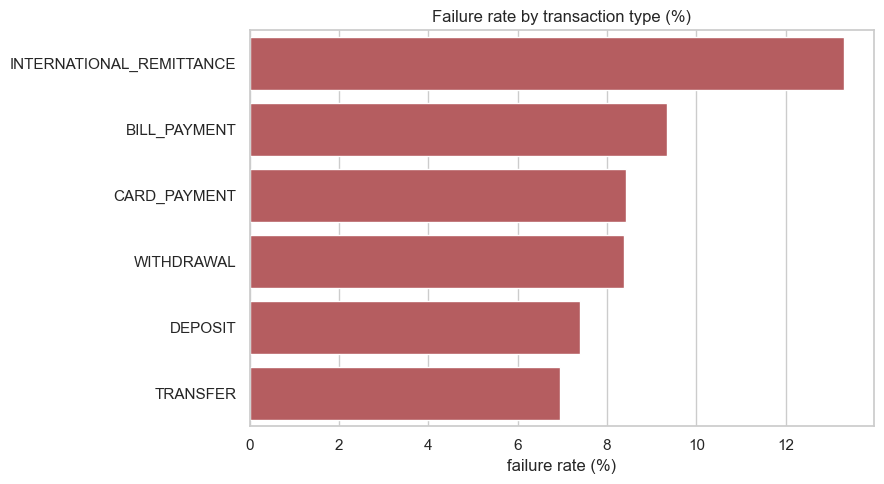

In [3]:
tt = q("""
    SELECT tt.type_name,
           count(*) AS total_txns,
           ROUND(100.0*count(*) FILTER (WHERE t.status='FAILED')/count(*),2) AS failure_rate_pct
    FROM transactions t JOIN transaction_types tt ON tt.type_id=t.transaction_type_id
    GROUP BY tt.type_name ORDER BY failure_rate_pct DESC
""")
display(tt)
sns.barplot(data=tt, x="failure_rate_pct", y="type_name", color="#C44E52")
plt.title("Failure rate by transaction type (%)"); plt.xlabel("failure rate (%)"); plt.ylabel("")
savefig("02_type_failure.png"); plt.show()


## 3. Transaction activity by origin country

*Business question: where is activity concentrated geographically?* Geography is
taken from the explicit `origin_country_id`, never inferred from currency.

,country_name,txn_count,pct_of_all
0,Nigeria,5877,14.69
1,Ghana,4197,10.49
2,Kenya,4176,10.44
3,United States,3957,9.89
4,United Kingdom,3787,9.47
5,Germany,3747,9.37
6,South Africa,3717,9.29
7,Canada,3597,8.99
8,India,3174,7.94
9,United Arab Emirates,3121,7.80


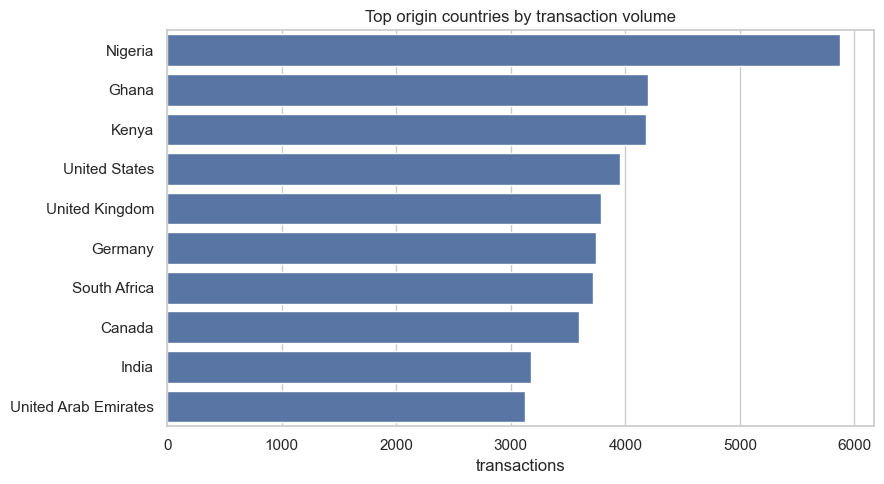

In [4]:
co = q("""
    SELECT co.country_name,
           count(*) AS txn_count,
           ROUND(100.0*count(*)/SUM(count(*)) OVER (),2) AS pct_of_all
    FROM transactions t JOIN countries co ON co.country_id=t.origin_country_id
    GROUP BY co.country_name ORDER BY txn_count DESC
""")
display(co.head(10))
sns.barplot(data=co.head(10), x="txn_count", y="country_name", color="#4C72B0")
plt.title("Top origin countries by transaction volume"); plt.xlabel("transactions"); plt.ylabel("")
savefig("03_country_activity.png"); plt.show()


## 4. Cross-border vs domestic activity

*Business question: what share of activity is cross-border?* An external/unknown
destination (`NULL`) is reported separately — not counted as domestic.

,geography,txn_count
0,domestic,32558
1,cross-border,6799
2,external/unknown,643


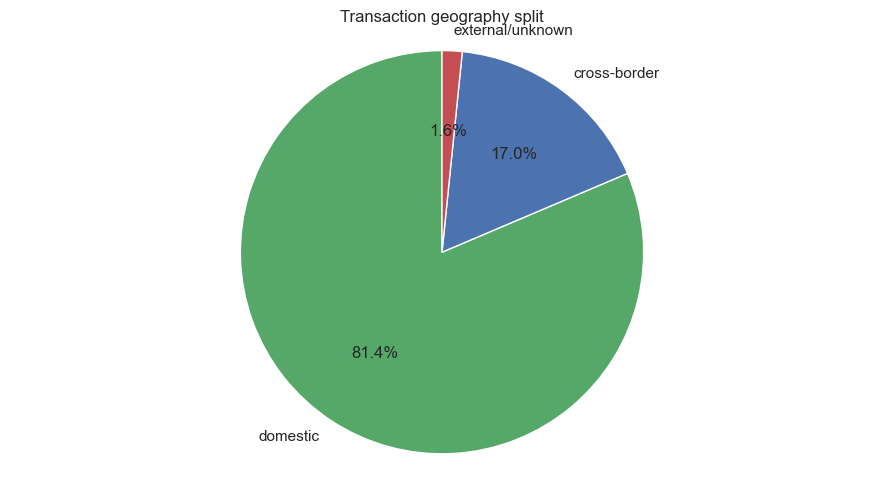

In [5]:
xb = q("""
    SELECT CASE
             WHEN destination_country_id IS NULL THEN 'external/unknown'
             WHEN destination_country_id = origin_country_id THEN 'domestic'
             ELSE 'cross-border' END AS geography,
           count(*) AS txn_count
    FROM transactions GROUP BY geography ORDER BY txn_count DESC
""")
display(xb)
plt.pie(xb["txn_count"], labels=xb["geography"], autopct="%1.1f%%",
        colors=["#55A868", "#4C72B0", "#C44E52"], startangle=90)
plt.title("Transaction geography split"); plt.axis("equal")
savefig("04_cross_border_split.png"); plt.show()


## 5. Transaction value distribution

*Business question: what does the spread of transaction sizes look like?*
Amounts are in the sending currency (not converted), so this is indicative.
A log scale is used because values are heavily right-skewed.

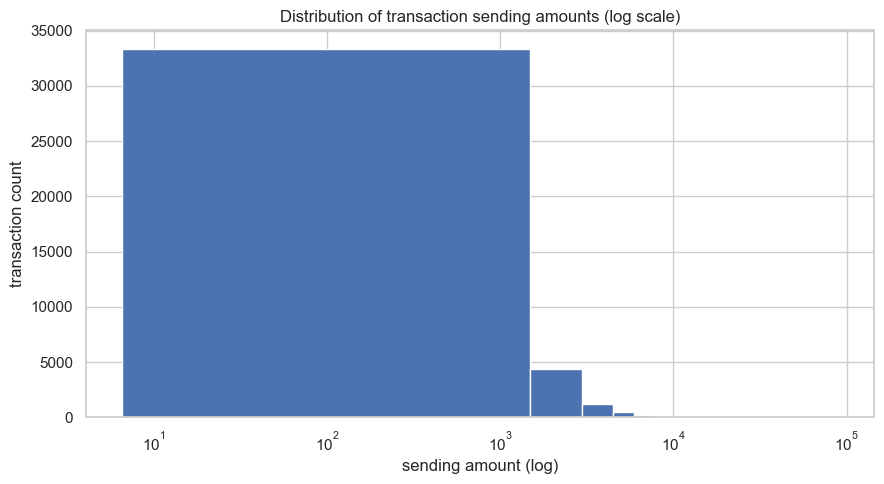

count    40000.00
mean       945.56
std       1588.56
min          6.58
25%        228.75
50%        493.52
75%       1072.43
max      89347.10


In [6]:
amt = q("SELECT sending_amount FROM transactions")
plt.hist(amt["sending_amount"], bins=60)
plt.xscale("log")
plt.title("Distribution of transaction sending amounts (log scale)")
plt.xlabel("sending amount (log)"); plt.ylabel("transaction count")
savefig("05_value_distribution.png"); plt.show()
print(amt["sending_amount"].describe().round(2).to_string())


## 6. Account transaction frequency

*Business question: are a few accounts much more active than the rest?* The
long right tail is where high-frequency indicators come from.

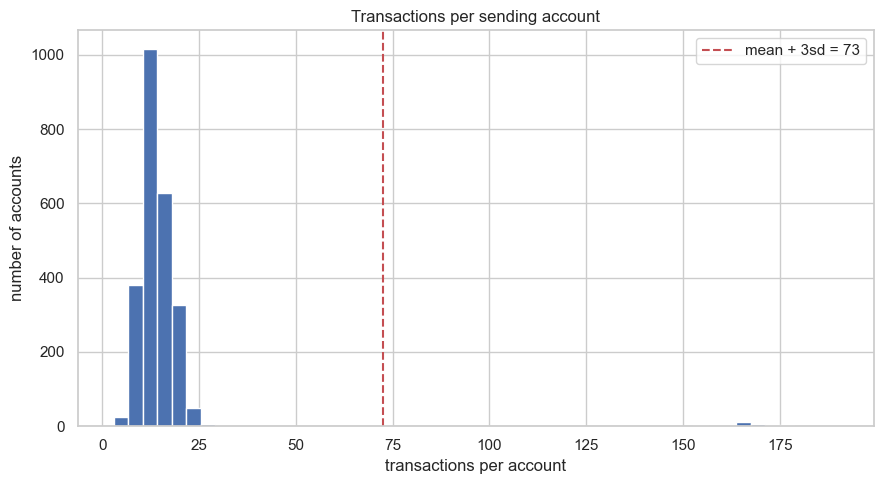

High-frequency accounts (> mean+3sd): 37


In [7]:
freq = q("""
    SELECT sender_account_id, count(*) AS txn_count
    FROM transactions GROUP BY sender_account_id
""")
plt.hist(freq["txn_count"], bins=50, color="#4C72B0")
plt.title("Transactions per sending account")
plt.xlabel("transactions per account"); plt.ylabel("number of accounts")
mean, sd = freq["txn_count"].mean(), freq["txn_count"].std()
thr = mean + 3*sd
plt.axvline(thr, color="#C44E52", linestyle="--", label=f"mean + 3sd = {thr:.0f}")
plt.legend()
savefig("06_account_frequency.png"); plt.show()
print(f"High-frequency accounts (> mean+3sd): {(freq['txn_count'] > thr).sum()}")


## 7. Login failure rate by channel

*Business question: how often do logins fail, and where?* (Digital-activity
indicator.)

,channel_name,total_logins,failure_rate_pct
0,INTERNET_BANKING,4445,8.62
1,ATM,774,8.40
2,MOBILE_APP,6733,8.01
3,PHONE_BANKING,1522,7.88
4,POS,774,7.11
5,BRANCH,752,6.91


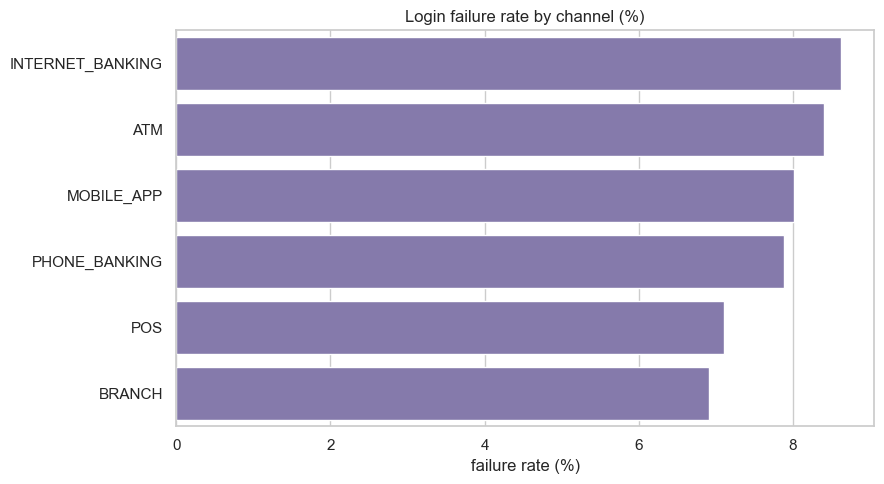

In [8]:
lg = q("""
    SELECT c.channel_name,
           count(*) AS total_logins,
           ROUND(100.0*count(*) FILTER (WHERE l.status='FAILED')/count(*),2) AS failure_rate_pct
    FROM login_events l JOIN channels c ON c.channel_id=l.channel_id
    GROUP BY c.channel_name ORDER BY failure_rate_pct DESC
""")
display(lg)
sns.barplot(data=lg, x="failure_rate_pct", y="channel_name", color="#8172B3")
plt.title("Login failure rate by channel (%)"); plt.xlabel("failure rate (%)"); plt.ylabel("")
savefig("07_login_failure.png"); plt.show()


## 8. Combined risk-indicator distribution

*Business question: how many customers trip several independent indicators at
once?* This is the transparent indicator **count** from
`sql/analysis/06_combined_risk_indicators.sql` (0–5, no weighting). A higher
count is a prompt to gather context, not a determination of risk.

,indicators_tripped,customer_count
0,0,1400
1,1,544
2,2,56


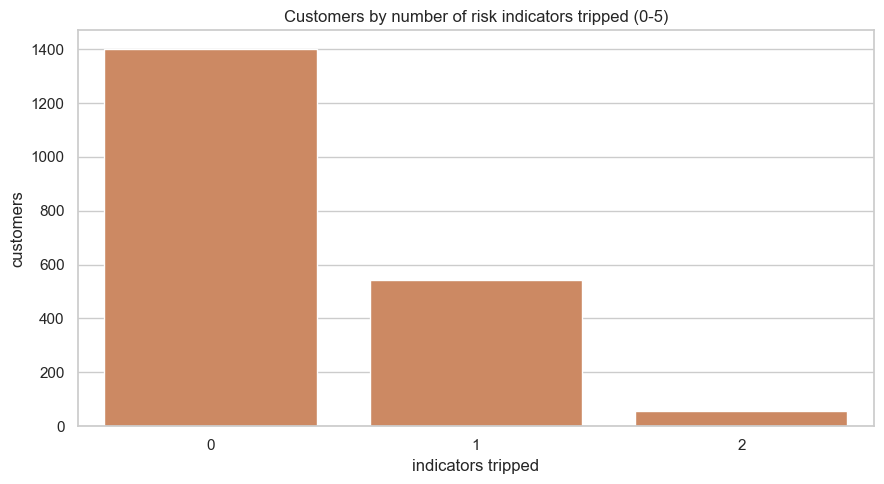

In [9]:
dist = q("""
WITH baseline AS (
  SELECT 1.0*count(*) FILTER (WHERE status='FAILED')/count(*) txn_fail_base,
         percentile_cont(0.99) WITHIN GROUP (ORDER BY sending_amount) high_value_p99
  FROM transactions),
ct AS (SELECT a.customer_id, count(*) txn_count,
              count(*) FILTER (WHERE t.status='FAILED') failed_txn,
              count(*) FILTER (WHERE t.destination_country_id IS NOT NULL
                                 AND t.destination_country_id<>t.origin_country_id) cross_border_txn,
              count(*) FILTER (WHERE t.sending_amount>=(SELECT high_value_p99 FROM baseline)) high_value_txn
       FROM transactions t JOIN accounts a ON a.account_id=t.sender_account_id GROUP BY 1),
cl AS (SELECT l.customer_id, count(*) login_count,
              count(*) FILTER (WHERE l.status='FAILED') failed_login,
              count(*) FILTER (WHERE l.origin_country_id IS NOT NULL
                                 AND l.origin_country_id<>c.country_id) geo_mismatch_login
       FROM login_events l JOIN customers c ON c.customer_id=l.customer_id GROUP BY 1),
scored AS (SELECT c.customer_id,
   (COALESCE(ct.txn_count>=10 AND 1.0*ct.failed_txn/ct.txn_count>2*(SELECT txn_fail_base FROM baseline),false)::int
  + COALESCE(cl.login_count>=5 AND 1.0*cl.failed_login/cl.login_count>0.25,false)::int
  + COALESCE(ct.txn_count>=10 AND 1.0*ct.cross_border_txn/ct.txn_count>0.50,false)::int
  + (COALESCE(ct.high_value_txn,0)>=1)::int
  + (COALESCE(cl.geo_mismatch_login,0)>=3)::int) AS indicators_tripped
   FROM customers c LEFT JOIN ct ON ct.customer_id=c.customer_id
                    LEFT JOIN cl ON cl.customer_id=c.customer_id)
SELECT indicators_tripped, count(*) AS customer_count
FROM scored GROUP BY indicators_tripped ORDER BY indicators_tripped
""")
display(dist)
sns.barplot(data=dist, x="indicators_tripped", y="customer_count", color="#DD8452")
plt.title("Customers by number of risk indicators tripped (0-5)")
plt.xlabel("indicators tripped"); plt.ylabel("customers")
savefig("08_indicator_distribution.png"); plt.show()


## Interpretation & limitations

**What the charts suggest (on this synthetic data):**
- Operational failures are not uniform: remote / self-service channels (POS,
  internet banking) and international remittances show the highest failure rates,
  while the staffed branch channel is lowest. This is the kind of concentration
  an operational-risk team would monitor.
- Activity is geographically concentrated in a handful of origin countries.
- Transaction values are heavily right-skewed; a small number of accounts are
  far more active than the rest (the long tail feeds the high-frequency/
  high-value indicators).
- Most customers trip **zero** indicators; only a small minority trip two or
  more — which is the intended behaviour of an interpretable indicator set.

**Limitations.**
- The data is synthetic; the *patterns were designed in*, so these results
  validate the analysis pipeline, not real-world risk.
- Amounts mix currencies and are not FX-normalised, so value totals are
  indicative only.
- Indicators are prompts for **context gathering**, not conclusions. A high
  cross-border share or a geo-mismatch has many innocent explanations
  (business accounts, travel, relocation).